# Project Work Part 4

- *Streamlit App* https://ind320-dakshi.streamlit.app
- *GitHub repo* https://github.com/dakshiken/IND320

## General (same as in part 3)
- If you push new updates to the main branch of your GitHub repository before the peer review and teacher feedback, things will get cluttered.
    - Create and use a new branch in the GitHub repository for new updates.
    - When peer review 3 and feedback 3 are finished, merge your changes into the main branch (see figure in Padlet).
- All project work in IND320 will result in personal hand-ins and online apps.
    1. A Jupyter Notebook run locally on your computer.
        - This will be your basic development and documentation platform.
            - Must include a brief description of AI usage.
            - Must include a 300-500-word log describing the compulsory work (including both Jupyter Notebook and Streamlit experience).
            - Must include links to your public GitHub repository and Streamlit app (see below) for the compulsory work.
            - Document headings should be clear and usable for navigation during development.
            - All code blocks must include enough comments to be understandable and reproducible if someone inherits your project.
            - All code blocks must be run before an export to PDF so the messages and plots are shown. In addition, add the .ipynb file to the GitHub repository where you have your Streamlit project.
    2. A Streamlit app running at https://[yourproject].streamlit.app/.
        - This is an online version of the project, accessing data that has been uploaded to your MongoDB database and data directly downloaded from Magasinstatistikk's API, open-meteo.com's API and the Norwegian Bank's API.
        - The code, hosted on GitHub, must include relevant comments from the Jupyter Notebook and further comments regarding Streamlit usage.
- There are four parts in the project work, building on each other and resulting in a final portfolio and app to be presented at the end of the semester.
- Co-operation is applauded, and the use of AI tools is encouraged.

## Tasks (new from here)
### Accounts and repositories
- Reuse your account, repository and Streamlit app from the previous part of the project work.
- Until peer review and feedback have been completed, push to a temporary GitHub branch for later merging.

## Jupyter Notebook
* Make a function for downloading Euro and USD currency exchange rates from the Norwegian Bank (NB) currency API and show that it works.

In [ ]:
import inspect
import json
import os
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import load_dotenv
from IPython.display import Markdown, display
from plotly.subplots import make_subplots
from river import linear_model, optim, preprocessing, time_series
from scipy.fft import dct, idct
from scipy.signal import spectrogram
from sklearn.neighbors import LocalOutlierFactor
from statsmodels.tsa.seasonal import STL

# paths are relative to the project root, like in the app
if Path.cwd().name == "notebooks":
    os.chdir("..")
load_dotenv(".env")                        # MONGO_URI

# hide Streamlit's "No runtime found" warnings (the modules are shared with the app)
import logging
import streamlit.config
streamlit.config.set_option("logger.level", "error")
for name in list(logging.root.manager.loggerDict):
    if name.startswith("streamlit"):
        logging.getLogger(name).setLevel(logging.ERROR)

from modules.theme import ALERT, BG, COPPER, MUTED, SAGE, SEQUENTIAL, SLATE, style   # same theme as the app


_warned = False


def show(fig):
    # static png for the PDF export (needs kaleido and Chrome), else the interactive figure
    global _warned
    fig.update_layout(paper_bgcolor=BG)          # the template is transparent, images need a background
    try:
        fig.show("png", width=900)
    except Exception as e:
        if not _warned:
            print("No static images (", type(e).__name__, "):", str(e)[:200], "\nFix: run `pip install -U kaleido plotly` and `plotly_get_chrome` in the terminal, then restart the kernel.")
            _warned = True
        fig.show()

In [ ]:
def download_rates(start, end, currencies=("EUR", "USD")):
    # one request for all currencies (EXR = exchange rates, B = business days, SP = spot)
    url = f"https://data.norges-bank.no/api/data/EXR/B.{'+'.join(currencies)}.NOK.SP"
    r = requests.get(url, params={"format": "sdmx-json", "startPeriod": start, "endPeriod": end}, timeout=60)
    r.raise_for_status()
    data = r.json()
    data = data.get("data", data)   # sometimes wrapped in "data"
    # series dimensions tell the currency, the observation dimension gives the dates
    dims = data["structure"]["dimensions"]["series"]
    dates = [v["id"] for v in data["structure"]["dimensions"]["observation"][0]["values"]]
    pos = [d["id"] for d in dims].index("BASE_CUR")
    rates = {}
    for key, series in data["dataSets"][0]["series"].items():
        currency = dims[pos]["values"][int(key.split(":")[pos])]["id"]
        rates[f"{currency}/NOK"] = pd.Series({dates[int(i)]: float(obs[0]) for i, obs in series["observations"].items()})
    df = pd.DataFrame(rates)
    df.index = pd.to_datetime(df.index)
    df.index.name = "Date"
    return df.sort_index()

(251, 2)


,USD/NOK,EUR/NOK
Date,,
2025-11-17,10.0927,11.7005
2025-11-18,10.1236,11.7333
2025-11-19,10.1425,11.7480
2025-11-20,10.1967,11.7405
2025-11-21,10.2378,11.7940


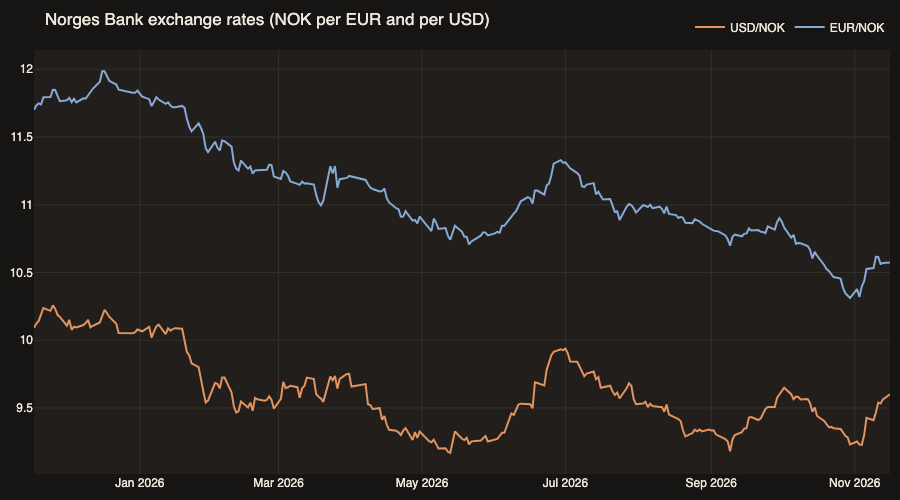

In [ ]:
# one year of rates
rates = download_rates("2025-11-16", "2026-11-16")
print(rates.shape)
display(rates.head())
fig = go.Figure([go.Scatter(x=rates.index, y=rates[c], name=c) for c in rates.columns])
show(style(fig, "Norges Bank exchange rates (NOK per EUR and per USD)"))


* download_rates(start, end) calls the Norges Bank API (dataflow EXR) once for both currencies and returns one column per currency (EUR/NOK, USD/NOk) and one row per business day. The table and the plot above show that it works. There are no rates on weekends and holidays.
* The function is saved as modules/currency.py and used by the pages Exchange rates and Forecast.

* Investigate possible timezone differences between Magasinstatistikk, ENTSO-E, OpenMeteo and NB and report your findings, plus solutions if needed.

In [ ]:
# NVE: what kind of time stamp does the API give? (raw is used later too)
BASE = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"
raw = pd.DataFrame(requests.get(f"{BASE}/HentOffentligData", timeout=60).json())
dates = pd.to_datetime(raw["dato_Id"])
print("example from the API:", raw["dato_Id"].iloc[0])
print("all dates at midnight (no time of day)?", bool(((dates.dt.hour == 0) & (dates.dt.minute == 0)).all()))
print("weekdays of the dates (0 = Monday, 6 = Sunday):", dates.dt.dayofweek.value_counts().to_dict())

example from the API: 2020-11-15
all dates at midnight (no time of day)? True
weekdays of the dates (0 = Monday, 6 = Sunday): {6: 14976}


In [ ]:
# Open-Meteo: same place, days around the switch to summer time, with and without the timezone parameter
def era5_times(tz=None):
    params = {"latitude": 63.4, "longitude": 10.4, "start_date": "2024-03-30", "end_date": "2024-04-01",
              "hourly": "temperature_2m", "models": "era5"}
    if tz:
        params["timezone"] = tz
    r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=60).json()
    return r["hourly"]["time"], r.get("timezone"), r.get("utc_offset_seconds")

for tz in (None, "Europe/Oslo"):
    times, name, offset = era5_times(tz)
    print(f"timezone={tz}: first {times[0]}, last {times[-1]}, {len(times)} rows, response timezone {name}, offset {offset} s")

timezone=None: first 2024-03-30T00:00, last 2024-04-01T23:00, 72 rows, response timezone GMT, offset 0 s
timezone=Europe/Oslo: first 2024-03-30T00:00, last 2024-04-01T23:00, 72 rows, response timezone Europe/Oslo, offset 3600 s


In [ ]:
# ENTSO-E (MongoDB): stored as UTC. Two time stamps, and the length of local days around the clock change
from pymongo import MongoClient

try:
    collection = MongoClient(os.getenv("MONGO_URI"), serverSelectionTimeoutMS=8000)["ind320"]["crossborder_flows"]
    doc = collection.find_one({}, {"_id": 0, "connection": 1, "ts": {"$slice": 2}})
    print("first time stamps of", doc["connection"], ":", doc["ts"], "(naive datetime from MongoDB = UTC)")
except Exception as e:
    print("MongoDB is not reachable here:", e)

# local days around the switch to summer time: Oslo has 23 hours on 2024-03-31, UTC always 24
local = pd.date_range("2024-03-30", "2024-04-02", freq="h", tz="Europe/Oslo", inclusive="left")
print("hours per local day:", pd.Series(1, index=local).groupby(local.date).sum().to_dict())
print("the same period in UTC:", local.tz_convert("UTC")[0], "to", local.tz_convert("UTC")[-1])

MongoDB is not reachable here: All nameservers failed to answer the query _mongodb._tcp.cluster0.zerwtcm.mongodb.net. IN SRV: Server Do53:128.39.235.155@53 answered REFUSED; Server Do53:128.39.235.156@53 answered REFUSED
hours per local day: {datetime.date(2024, 3, 30): 24, datetime.date(2024, 3, 31): 23, datetime.date(2024, 4, 1): 24}
the same period in UTC: 2024-03-29 23:00:00+00:00 to 2024-04-01 21:00:00+00:00


In [ ]:
# Norges Bank: a date per observation, business days only
print("index type:", rates.index.dtype, "| weekdays that occur (0 = Monday):", sorted(rates.index.dayofweek.unique()))
print("days without a rate in the table above:", len(pd.date_range(rates.index.min(), rates.index.max())) - len(rates))

index type: datetime64[us] | weekdays that occur (0 = Monday): [0, 1, 2, 3, 4]
days without a rate in the table above: 114


![alt text](IMG_1224.jpg)

* **Solution:** every hourly source is converted to Norwegian time (to_oslo) and averaged to weeks that end on Sunday (weekly_extra). The weekly means are matched to the NVE dates (nearest date within three days). The printouts above are the facts behind the table.
* Using the River framework, make a function for SARIMAX or a lag-based Machine Learning with predictions of the coming months' fillings for a single region (according to Magasinstatistikk), letting relevant model parameters, length of history and horizon, and selection of data sources be inputs to the function.

In [ ]:
def download_weather(region, start, end, n_points=50,
                     variables=("temperature_2m", "precipitation", "rain", "snowfall", "wind_speed_10m", "wind_gusts_10m")):
    # same random points every time (file from part 3)
    points = random.Random(0).sample(json.load(open("data/sample_points.json"))[region], n_points)
    frames = []
    # max 10 points per request
    for i in range(0, n_points, 10):
        batch = points[i:i + 10]
        params = {"latitude": ",".join(str(lat) for lon, lat in batch), "longitude": ",".join(str(lon) for lon, lat in batch),
                  "start_date": start, "end_date": end, "hourly": ",".join(variables), "models": "era5"}
        for attempt in range(3):
            r = requests.get("https://archive-api.open-meteo.com/v1/archive", params=params, timeout=120)
            if r.status_code != 429:
                break
            time.sleep(60)             # rate limit (600 calls/min): wait, retry
        if r.status_code != 200:
            raise RuntimeError(r.json().get("reason", r.text[:200]))
        data = r.json()
        # one point gives a dict, several give a list
        for loc in data if isinstance(data, list) else [data]:
            frames.append(pd.DataFrame(loc["hourly"]).set_index("time").rename(columns=lambda c: c.removesuffix("_era5")))
    # mean over the points
    weather = pd.concat(frames).groupby(level=0).mean()
    weather.index = pd.to_datetime(weather.index)
    return weather

In [ ]:
def to_oslo(df):
    # UTC time stamps -> Norwegian time
    out = df.copy()
    out.index = out.index.tz_localize("UTC").tz_convert("Europe/Oslo").tz_localize(None)
    return out


def weekly_extra(weather=None, rates=None, flows=None):
    # all sources on one weekly index (weeks end on Sunday, like the NVE dates)
    parts = []
    if weather is not None:
        parts.append(to_oslo(weather).resample("W-SUN").mean())          # hourly UTC -> Oslo -> week
    if rates is not None:
        parts.append(rates.resample("W-SUN").mean().ffill())             # business days -> week, gaps filled forward
    if flows is not None:
        parts.append(flows.resample("W-SUN").mean())                     # hourly, already Oslo time
    return pd.concat(parts, axis=1)


def forecast_fill(fill, extra=None, exog=(), origin=None, horizon=26, history=260,
                  p=2, d=0, q=1, m=52, sp=1, sd=0, sq=0, lr=0.05, epochs=10,
                  future="seasonal", interval=False, quantiles=(0.1, 0.9), interval_epochs=20):
    # SNARIMAX forecast of the weekly fill degree for one region
    # fill: weekly series, extra: weekly table of all sources, exog: columns of extra to use
    exog = list(exog)
    data = fill.interpolate().to_frame("y")
    if exog:
        data = data.join(extra[exog].reindex(data.index, method="nearest", tolerance=pd.Timedelta("3D")))
    origin = data.index[-1] if origin is None else pd.Timestamp(origin)
    # train on the last `history` weeks before the origin, complete rows only
    train = data.loc[:origin].dropna().tail(history)
    if len(train) < max(30, 2 * (p + q)):
        raise ValueError(f"only {len(train)} weeks of training data, too few for this model")
    dates = pd.date_range(train.index[-1] + pd.Timedelta(weeks=1), periods=horizon, freq="7D")

    # exog values for the horizon: real ones ("actual", back-test only) or the mean of the same week in the training data
    weeks = train.index.isocalendar().week.values
    seasonal = train[exog].groupby(weeks).mean() if exog else None
    xs = []
    for t in dates:
        row = {}
        for c in exog:
            real = data[c].get(t, np.nan) if future == "actual" else np.nan
            week = t.isocalendar().week
            row[c] = real if pd.notna(real) else (seasonal.loc[week, c] if week in seasonal.index else train[c].mean())
        xs.append(row)
    rows = list(zip(train["y"].values, [dict(zip(exog, v)) for v in train[exog].to_numpy()]))

    def fit_forecast(loss=None, passes=epochs):
        # learns one week at a time; a few passes over the history help
        reg = linear_model.LinearRegression(optimizer=optim.SGD(lr), intercept_lr=lr, **({"loss": loss} if loss else {}))
        model = time_series.SNARIMAX(p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq, regressor=preprocessing.StandardScaler() | reg)
        for _ in range(passes):
            for y, x in rows:
                model.learn_one(y, x)
        return np.array(model.forecast(horizon, xs=xs))      # dynamic: each step uses the earlier forecasts

    t0 = time.time()
    top = max(1, fill.max())
    result = pd.DataFrame({"forecast": np.clip(fit_forecast(), 0, top)}, index=dates)
    if interval:
        # one model per quantile: lower and upper limit
        low, high = (np.clip(fit_forecast(optim.losses.Quantile(a), interval_epochs), 0, top) for a in quantiles)
        result["lower"] = np.minimum(low, result["forecast"])
        result["upper"] = np.maximum(high, result["forecast"])
    result["actual"] = fill.reindex(dates)
    err = (result["forecast"] - result["actual"]).abs().dropna()
    return result, {"mae": err.mean() if len(err) else np.nan, "n_train": len(train), "seconds": time.time() - t0,
                    "train_start": train.index[0], "train_end": train.index[-1]}


def forecast_plot(fill, result, weeks_before=104, animate=True):
    # history, forecast (animated, grows week by week) and optional interval
    first = result.index[0]
    past = fill[first - pd.Timedelta(weeks=weeks_before): first - pd.Timedelta(days=1)]
    dates = list(result.index)
    has_band = "lower" in result
    color = COPPER

    def band(k):          # interval as a polygon over the first k weeks
        if not has_band:
            return go.Scatter(x=[], y=[])
        x = dates[:k] + dates[:k][::-1]
        y = list(result["upper"][:k]) + list(result["lower"][:k])[::-1]
        return go.Scatter(x=x, y=y, fill="toself", mode="none", fillcolor="rgba(227,147,95,0.25)", name="Interval", hoverinfo="skip")

    def line(k):
        return go.Scatter(x=dates[:k], y=result["forecast"][:k], mode="lines+markers", name="Forecast", line=dict(color=color), marker=dict(size=5))

    fig = go.Figure([
        go.Scatter(x=past.index, y=past.values, mode="lines", name="Observed (history)", line=dict(color=SLATE)),
        go.Scatter(x=dates, y=result["actual"], mode="lines", name="Observed (forecast period)", line=dict(color=SAGE, dash="dot")),
        band(len(dates)), line(len(dates))])
    if animate:
        fig.frames = [go.Frame(name=str(k), data=[band(k), line(k)], traces=[2, 3]) for k in range(1, len(dates) + 1)]
        fig.update_layout(
            updatemenus=[dict(type="buttons", direction="left", x=0, y=-0.15, showactive=False, buttons=[
                dict(label="▶ Play", method="animate", args=[None, {"frame": {"duration": 150, "redraw": True}, "fromcurrent": True}]),
                dict(label="⏸ Pause", method="animate", args=[[None], {"frame": {"duration": 0}, "mode": "immediate"}])])],
            sliders=[dict(x=0.15, len=0.85, y=-0.1, currentvalue=dict(prefix="Weeks ahead: "), steps=[
                dict(label=str(k), method="animate", args=[[str(k)], {"frame": {"duration": 0, "redraw": True}, "mode": "immediate"}])
                for k in range(1, len(dates) + 1)])])
    # fixed axes, no jumping while it plays
    values = np.concatenate([past.values, result.to_numpy().ravel()])
    values = values[~np.isnan(values)]
    pad = 0.05 * (values.max() - values.min())
    fig.update_yaxes(range=[values.min() - pad, values.max() + pad], title_text="Fill degree")
    fig.update_xaxes(range=[past.index[0] if len(past) else first, dates[-1]])
    return style(fig, "Forecast of the fill degree")


* Reduced number of weather locations: data/sample_points.json holds 1000 random points per area (from part 3), but the free Open-Meteo API limits the calls (600 per minute, 5,000 per hour) and a request takes at most 10 locations. I therefore use a fixed random sample of the 1000 points: 50 locations for one year of one property (*Weather anomalies*) and 10 locations for multi-year downloads (the map, *Correlation*, *Forecast* and this notebook), averaged over the area. Every year is cached, so it is downloaded once. The mean over fewer points is a little noisier than a mean over 1000.
* River's SARIMAX is time_series.SNARIMAX. The regressor is StandardScaler() | LinearRegression, so the extra variables are scaled and learned together with the lags.
* forecast_fill(...) forecasts one region. fill is the weekly series from Magasinstatistikk, extra the weekly table of the other sources and exog the columns used. History, horizon and all model parameters are inputs.
* weekly_extra puts weather (Open-Meteo), exchange rates (Norges Bank) and flows (ENTSO-E) on one weekly index.
* The forecast is dynamic: each forecast week is fed back into the lags. The extra variables in the horizon are the real values (future="actual", back-test) or the mean of the same week in the training data (future="seasonal", the only honest choice for the real future).
* Bonus: interval=True trains two more models with optim.losses.Quantile for the lower and upper limit.

In [ ]:
# test data: EL 3 (NO3)
AREA = "EL 3"
fill = (raw[(raw["omrType"] == "EL") & (raw["omrnr"] == 3)]
        .assign(Date=lambda d: pd.to_datetime(d["dato_Id"])).set_index("Date")["fyllingsgrad"].sort_index())

def weather_hourly(area, first_year, last_year, variables, n_points=10):
    # one file per year in data/cache, so reruns do not download again
    Path("data/cache").mkdir(parents=True, exist_ok=True)
    frames = []
    for year in range(first_year, last_year + 1):
        file = Path(f"data/cache/{area.replace(' ', '')}_{year}_{'-'.join(variables)}_{n_points}.csv")
        if not file.exists():
            end = min(pd.Timestamp(f"{year}-12-31"), pd.Timestamp.today().normalize() - pd.Timedelta(days=7))
            download_weather(area, f"{year}-01-01", end.strftime("%Y-%m-%d"), n_points, variables).to_csv(file)
        frames.append(pd.read_csv(file, index_col=0, parse_dates=True))
    return pd.concat(frames)

# 10 points per year keeps the download under the rate limit
weather = weather_hourly(AREA, 2014, pd.Timestamp.today().year, ("temperature_2m", "precipitation", "snowfall"))
all_rates = download_rates("2014-01-01", pd.Timestamp.today().strftime("%Y-%m-%d"))
extra = weekly_extra(weather=weather, rates=all_rates)
print(extra.shape, "weekly rows; columns:", list(extra.columns))

(674, 5) weekly rows; columns: ['temperature_2m', 'precipitation', 'snowfall', 'USD/NOK', 'EUR/NOK']


{'mae': np.float64(0.1536), 'n_train': 260, 'seconds': 0.1279, 'train_start': Timestamp('2021-06-06 00:00:00'), 'train_end': Timestamp('2026-05-24 00:00:00')}


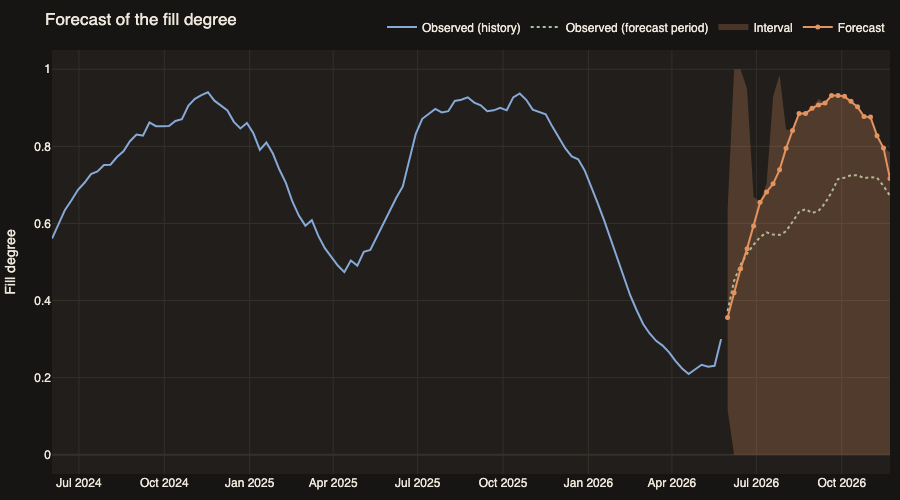

In [ ]:
# back-test: hide the last 26 weeks, forecast them with the real weather
origin = fill.index[-27]
result, info = forecast_fill(fill, extra, exog=["temperature_2m", "precipitation"], origin=origin, horizon=26, future="actual", interval=True)
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in info.items()})
show(forecast_plot(fill, result, animate=False))

In [ ]:
# ENTSO-E flows as a source (MongoDB starts in 2024, so the history is short)
try:
    from modules.mongo import get_net_flow
    extra_flows = weekly_extra(weather=weather, flows=get_net_flow())
    res, inf = forecast_fill(fill, extra_flows, exog=["temperature_2m", "net_export_MW"], origin=origin, horizon=26, history=260, future="actual")
    print("with net export as exogenous variable: trained on", inf["n_train"], "weeks, MAE", round(inf["mae"], 4))
except Exception as e:
    print("flows not available here:", e)

with net export as exogenous variable: trained on 125 weeks, MAE 0.1943



* The figure shows 26 weeks of EL 3 that the model has not seen: real values (dotted), forecast and the 80 % interval.
* Only weeks where all chosen variables exist are used for training, so adding the flows shortens the history to the weeks since 2024.

* Choose a reasonable time resolution for your input data so the function doesn't use an unreasonable amount of time while still performing well. Include findings in the report.

In [ ]:
# time for one pass over ten years at three resolutions (m follows the resolution)
def pass_time(y, m):
    model = time_series.SNARIMAX(p=2, d=0, q=1, m=m, sp=1,
                                 regressor=preprocessing.StandardScaler() | linear_model.LinearRegression(optimizer=optim.SGD(0.05), intercept_lr=0.05))
    t0 = time.time()
    for v in y:
        model.learn_one(v)
    return time.time() - t0

ten_years = fill["2015":"2024"]
resolutions = {"weekly": (ten_years, 52), "daily": (ten_years.resample("D").interpolate(), 365), "hourly": (ten_years.resample("h").interpolate(), 8760)}
timing = pd.DataFrame({name: {"points": len(y), "seconds per pass": round(pass_time(y, m), 2)} for name, (y, m) in resolutions.items()}).T
display(timing)

,points,seconds per pass
weekly,522.0,0.00
daily,3648.0,0.02
hourly,87529.0,0.48



* Weekly resolution. Magasinstatistikk is weekly, so a finer resolution only adds interpolated copies. Points and time per pass grow by about 7 (daily) and 168 (hourly), and the seasonal period `m` from 52 to 365 or 8760.
* The hourly and daily sources are averaged to weeks in `weekly_extra`, after the timezone conversion. A forecast then trains in a fraction of a second, which works in Streamlit.

* Test the function for various settings, report your findings (how you tested and your experiences) and let the best solution be the default setting when used in Streamlit.

In [ ]:
# back-test: 26 weeks ahead from many origins, mean absolute error (MAE)
# "seasonal" = no real future weather, as in the app; "oracle" = real weather, upper bound
ORIGINS = list(fill["2021-01-01":"2025-12-31"].index[::4])      # about 65 origins
BASE_SET = dict(p=2, d=0, q=1, m=52, sp=1, sd=0, sq=0, history=260, epochs=10, lr=0.05)
WX = ["temperature_2m", "precipitation", "snowfall"]
SETTINGS = {
    "AR(2), no seasonality": dict(BASE_SET, q=0, m=1, sp=0),
    "ARMA(2,1) + seasonal lag (52)": BASE_SET,
    "seasonal + differencing (d=1)": dict(BASE_SET, d=1),
    "seasonal + temperature": dict(BASE_SET, exog=["temperature_2m"]),
    "seasonal + temperature + precipitation": dict(BASE_SET, exog=WX[:2]),
    "seasonal + temperature + precipitation + snowfall": dict(BASE_SET, exog=WX),
    "seasonal + EUR/NOK and USD/NOK": dict(BASE_SET, exog=["EUR/NOK", "USD/NOK"]),
    "seasonal + weather + currency": dict(BASE_SET, exog=WX + ["EUR/NOK", "USD/NOK"]),
    "weather, history 156 weeks": dict(BASE_SET, exog=WX, history=156),
    "weather, history 364 weeks": dict(BASE_SET, exog=WX, history=364),
    "weather, 5 passes": dict(BASE_SET, exog=WX, epochs=5),
    "weather, 20 passes": dict(BASE_SET, exog=WX, epochs=20),
    "weather, learning rate 0.01": dict(BASE_SET, exog=WX, lr=0.01),
    "weather, learning rate 0.005": dict(BASE_SET, exog=WX, lr=0.005),
    "weather, learning rate 0.002": dict(BASE_SET, exog=WX, lr=0.002),
    "temperature + precipitation, learning rate 0.01": dict(BASE_SET, exog=WX[:2], lr=0.01),
    "weather, learning rate 0.01, 20 passes": dict(BASE_SET, exog=WX, lr=0.01, epochs=20),
    "weather, learning rate 0.01, history 364 weeks": dict(BASE_SET, exog=WX, lr=0.01, history=364),
    "weather, p=4, q=2": dict(BASE_SET, exog=WX, p=4, q=2),
    "weather, oracle: real weather in the horizon": dict(BASE_SET, exog=WX, future="actual"),
}

def backtest(**settings):
    errors, secs = [], 0
    for o in ORIGINS:
        _, inf = forecast_fill(fill, extra, origin=o, horizon=26, **settings)
        errors.append(inf["mae"])
        secs += inf["seconds"]
    return np.mean(errors), secs / len(ORIGINS)

# reference: same week last year
def naive_mae(o):
    weeks = fill.index[fill.index > o][:26]
    last_year = fill.reindex(weeks - pd.Timedelta(weeks=52), method="nearest").values
    return np.abs(fill.reindex(weeks).values - last_year).mean()

naive = np.mean([naive_mae(o) for o in ORIGINS])
rows = {"naive: same week last year": (naive, 0.0)}
rows.update({name: backtest(**s) for name, s in SETTINGS.items()})
results = pd.DataFrame(rows, index=["MAE", "seconds per forecast"]).T.sort_values("MAE")
results["oracle"] = results.index.str.contains("oracle")
display(results.round(4))

,MAE,seconds per forecast,oracle
"weather, learning rate 0.002",0.0927,0.0241,False
"weather, learning rate 0.005",0.0947,0.0241,False
"temperature + precipitation, learning rate 0.01",0.1011,0.0222,False
"weather, learning rate 0.01, 20 passes",0.1013,0.0479,False
"weather, learning rate 0.01",0.1014,0.0239,False
"weather, learning rate 0.01, history 364 weeks",0.1031,0.0336,False
naive: same week last year,0.1180,0.0000,False
seasonal + temperature,0.1277,0.0198,False
seasonal + temperature + precipitation,0.1313,0.0221,False
"weather, oracle: real weather in the horizon",0.1326,0.0241,True


In [ ]:
# best realistic setting (not naive, not oracle) = default in the app
realistic = results[~results["oracle"] & (results.index != "naive: same week last year")]
best_name = realistic.index[0]
best = {k: v for k, v in SETTINGS[best_name].items()}
best.setdefault("exog", [])
best["future"] = "seasonal"
Path("data").mkdir(exist_ok=True)
json.dump(best, open("data/forecast_defaults.json", "w"), indent=2)
better = results.loc["naive: same week last year", "MAE"] - realistic.iloc[0]["MAE"]
display(Markdown(f"**Best realistic setting: {best_name}** (MAE {realistic.iloc[0]['MAE']:.4f}, the naive reference has {results.loc['naive: same week last year', 'MAE']:.4f}; "
                 f"{'better' if better > 0 else 'not better'} than the reference). Saved in `data/forecast_defaults.json`:"))
print(json.dumps(best))

**Best realistic setting: weather, learning rate 0.002** (MAE 0.0927, the naive reference has 0.1180; better than the reference). Saved in `data/forecast_defaults.json`:

{"p": 2, "d": 0, "q": 1, "m": 52, "sp": 1, "sd": 0, "sq": 0, "history": 260, "epochs": 10, "lr": 0.002, "exog": ["temperature_2m", "precipitation", "snowfall"], "future": "seasonal"}


In [ ]:
# interval check: do the 10 % and 90 % models cover about 80 %?
def coverage(passes):
    hits, widths = [], []
    for o in ORIGINS:
        res, _ = forecast_fill(fill, extra, origin=o, horizon=26, interval=True, interval_epochs=passes, **best)
        ok = res.dropna(subset=["actual"])
        hits += list((ok["actual"] >= ok["lower"]) & (ok["actual"] <= ok["upper"]))
        widths += list(ok["upper"] - ok["lower"])
    return {"coverage (target 0.80)": round(float(np.mean(hits)), 2), "mean width": round(float(np.mean(widths)), 3)}

interval_table = pd.DataFrame({f"{n} passes": coverage(n) for n in (1, 10, 20, 40)}).T
display(interval_table)

,coverage (target 0.80),mean width
1 passes,0.49,0.537
10 passes,0.85,0.401
20 passes,0.86,0.421
40 passes,0.89,0.457



* **Test:** rolling-origin back-test. About 65 origins (every 4 weeks, 2021 to 2025): train on the history before the origin, forecast 26 weeks, compare with the real values. The table gives the mean absolute error (MAE) and the time per forecast, with the same origins for every setting. Reference: the same week last year.
* **Varied:** the lags (AR, ARMA, seasonal lag 52, differencing), the sources (temperature, precipitation, snowfall, exchange rates), history (156, 260, 364 weeks), passes (5, 10, 20) and learning rate (0.05 to 0.002). The *oracle* row uses the real weather in the horizon. It is an upper bound only, so it cannot be the default.
* **Result:** the table is sorted by MAE and the cell below writes the best realistic setting to `data/forecast_defaults.json`. The *Forecast* page reads that file, so the best solution is the default there.
* **Experiences:** the seasonal lag matters most, since the fill degree follows the year. Differencing and exchange rates made it worse, because an online learner struggles with series that drift. The learning rate mattered more than the number of passes (a high rate made the weights jump). A longer history helped a little. The best setting is only moderately better than the naive reference, so half a year ahead stays uncertain. The last table shows coverage and width of the 80 % interval for 1 to 40 passes.

* Include the sketch mentioned in "Streamlit app, refactoring -> Structure and navigation" below.

![alt text](IMG_1224.jpg)

* Remember to fill in the log and AI mentioned in the General section above.

## Streamlit app, refactoring
### Theme
- If you haven't already, choose colours, graphical elements, etc. that you find pleasing and consistent.

- choose tinger color theme , beacause i like tigers and didnt want to pick colors normally people would choose like blue or some water colors , wanted to stand out and contrast really good (black and orange)

### Plotting
- Exchange all static plots (matplotlib/seaborn) with dynamic plots (Plotly, Streamlit, Bokeh, ...).
- Theme your plots to match the overall app theme.

In [ ]:
# the analysis functions from part 3 in Plotly (figure + summary)
def spc_outliers(series, cutoff=0.03, n_std=3.0, label="value"):
    x = series.interpolate().bfill().ffill()
    # DCT high-pass: zero the low frequencies
    coef = dct(x.values, norm="ortho")
    coef[: int(cutoff * 2 * len(x) / 24)] = 0
    satv = idct(coef, norm="ortho")                           # seasonally adjusted variation (SATV)
    centre = np.median(satv)
    sigma = 1.4826 * np.median(np.abs(satv - centre))        # robust std (MAD)
    out = np.abs(satv - centre) > n_std * sigma
    mid = x.values - satv + centre                           # slow part: limits follow the season
    limit = dict(color=MUTED, dash="dash", width=1)
    fig = go.Figure()
    fig.add_scatter(x=x.index, y=x.values, mode="lines", name=label, line=dict(width=1))
    fig.add_scatter(x=x.index, y=mid + n_std * sigma, mode="lines", name=f"Limits ({n_std:g} robust std)", line=limit)
    fig.add_scatter(x=x.index, y=mid - n_std * sigma, mode="lines", showlegend=False, line=limit)
    fig.add_scatter(x=x.index[out], y=x.values[out], mode="markers", name="Outliers", marker=dict(color=ALERT, size=5))
    fig.update_yaxes(title_text=label)
    return style(fig), {"n": len(x), "outliers": int(out.sum()), "share": out.mean(), "robust_std": sigma,
                        "table": x[out].to_frame(label)}


def lof_anomalies(series, contamination=0.01, n_neighbors=20, label="value"):
    x = series.interpolate().bfill().ffill()
    # value in std units, time scaled to 0-20, so both count for the neighbours
    points = np.c_[(x.values - x.mean()) / x.std(), np.linspace(0, 20, len(x))]
    lof = LocalOutlierFactor(n_neighbors=n_neighbors, contamination=contamination)
    flag = lof.fit_predict(points) == -1                      # -1 = anomaly
    fig = go.Figure()
    fig.add_scatter(x=x.index, y=x.values, mode="lines", name=label, line=dict(width=1))
    fig.add_scatter(x=x.index[flag], y=x.values[flag], mode="markers", name="Anomalies", marker=dict(color=ALERT, size=6))
    fig.update_yaxes(title_text=label)
    table = pd.DataFrame({label: x[flag], "LOF score": -lof.negative_outlier_factor_[flag]}).sort_values("LOF score", ascending=False)
    return style(fig), {"n": len(x), "anomalies": int(flag.sum()), "share": flag.mean(), "table": table}


def stl_plot(series, seasonal=13, trend=105, robust=True):
    # STL on a regular weekly grid, one panel per component
    res = STL(series.asfreq("7D").interpolate(), period=52, seasonal=seasonal, trend=trend, robust=robust).fit()
    parts = {"Observed": res.observed, "Trend": res.trend, "Seasonal": res.seasonal, "Residual": res.resid}
    fig = make_subplots(rows=4, cols=1, shared_xaxes=True, vertical_spacing=0.03)
    for i, (name, part) in enumerate(parts.items(), start=1):
        fig.add_scatter(x=part.index, y=part.values, mode="lines", name=name, showlegend=False, line=dict(width=1), row=i, col=1)
        fig.update_yaxes(title_text=name, row=i, col=1)
    return style(fig, f"STL: seasonal={seasonal}, trend={trend}, robust={robust}", height=650)


def spectrogram_plot(series, window=156, overlap=78):
    f, t, power = spectrogram(series.interpolate().values, fs=52, nperseg=window, noverlap=overlap)   # 52 samples per year
    keep = f <= 6                                              # 0-6 cycles per year
    fig = go.Figure(go.Heatmap(x=series.index[0].year + t, y=f[keep], z=10 * np.log10(power[keep]),
                               colorscale=SEQUENTIAL, zsmooth="best", colorbar=dict(title="Power (dB)")))
    fig.update_layout(xaxis_title="Year", yaxis_title="Frequency (cycles per year)")
    return style(fig, f"Window {window} weeks, overlap {overlap} weeks")


def sliding_correlation(x, y, lag=0, window=52):
    # x at week t against y at t + lag (positive lag: x first); weekly series
    y = y.dropna()
    x = x.reindex(y.index, method="nearest", tolerance=pd.Timedelta("3D"))    # match weeks, 3 days apart at most
    shifted = y.shift(-lag)
    rolling = x.rolling(window, center=True).corr(shifted)             # correlation in a sliding window
    cross = pd.Series({k: x.corr(y.shift(-k)) for k in range(-26, 27)})  # every lag
    ahead = cross[cross.index >= 0]                                     # weather first = usable for forecasting
    best = ahead.abs().idxmax()
    z = lambda s: (s - s.mean()) / s.std()
    fig = make_subplots(rows=3, cols=1, vertical_spacing=0.1, subplot_titles=(
        f"Standardised series ({y.name} moved {lag} weeks)", f"Sliding window correlation ({window} weeks)", "Correlation at every lag (whole period)"))
    fig.add_scatter(x=x.index, y=z(x), name=str(x.name), mode="lines", line=dict(width=1), row=1, col=1)
    fig.add_scatter(x=x.index, y=z(shifted), name=f"{y.name} (lag {lag})", mode="lines", line=dict(width=1), row=1, col=1)
    fig.add_scatter(x=rolling.index, y=rolling, name="Sliding correlation", mode="lines", line=dict(color=COPPER), row=2, col=1)
    fig.add_hline(y=0, line_dash="dot", line_color=MUTED, row=2, col=1)
    fig.add_bar(x=cross.index, y=cross.values, name="Correlation", showlegend=False, row=3, col=1,
                marker_color=[COPPER if k == lag else SLATE for k in cross.index])
    fig.update_xaxes(title_text="Lag (weeks)", row=3, col=1)
    fig.update_yaxes(range=[-1, 1], row=2, col=1)
    fig.update_yaxes(range=[-1, 1], row=3, col=1)
    fig.update_layout(legend_y=1.05)                                    # room for the first subplot title
    return style(fig, height=800), {"overall": x.corr(shifted), "best_lag": int(best), "best_corr": cross[best], "rolling": rolling}

{'n': 8784, 'outliers': 10, 'share': np.float64(0.001138433515482696), 'robust_std': np.float64(3.234100374164814)}


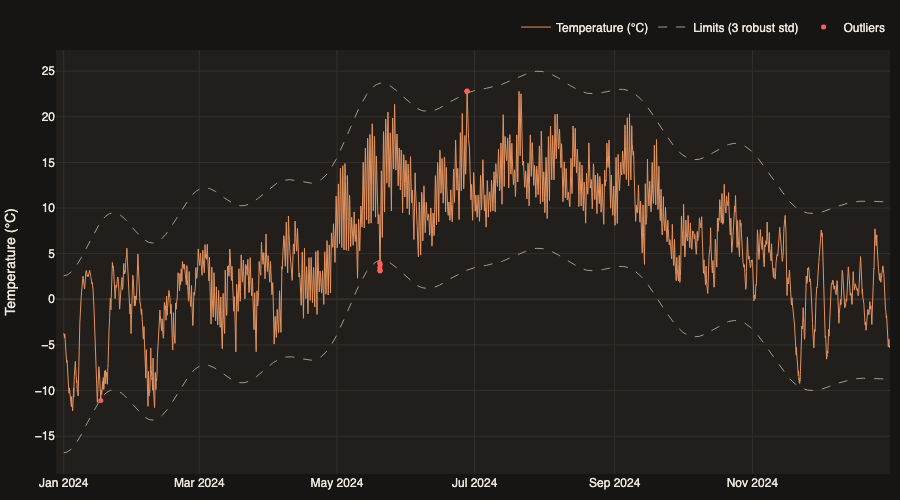

{'n': 8784, 'anomalies': 88, 'share': np.float64(0.010018214936247723)}


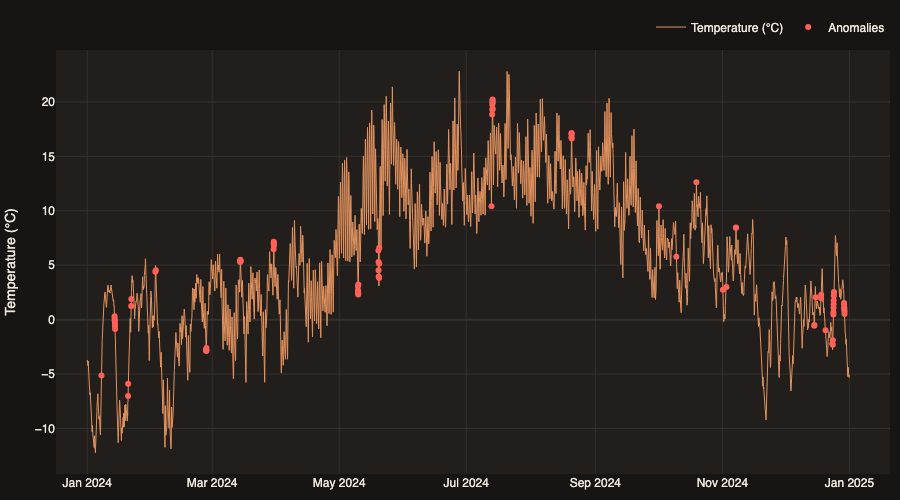

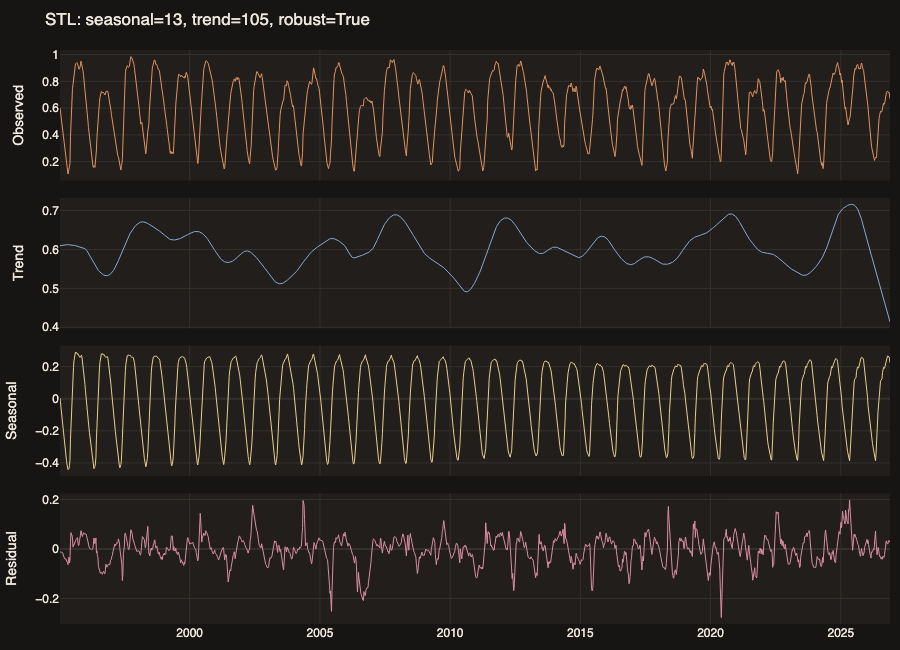

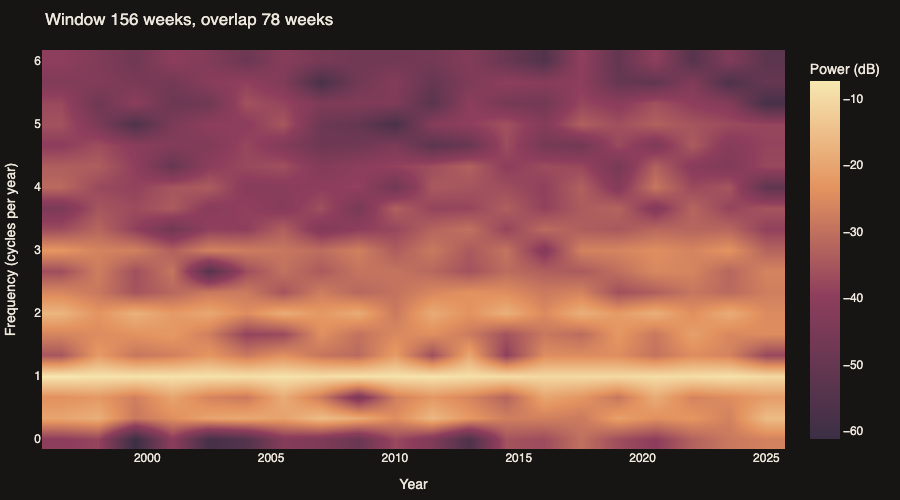

In [ ]:
# test: temperature for EL 3 in 2024, fill degree for the weekly plots
t2024 = download_weather(AREA, "2024-01-01", "2024-12-31", variables=("temperature_2m",))["temperature_2m"]
fig, summary = spc_outliers(t2024, label="Temperature (°C)")
print({k: v for k, v in summary.items() if k != "table"})
show(fig)
fig, summary = lof_anomalies(t2024, label="Temperature (°C)")
print({k: v for k, v in summary.items() if k != "table"})
show(fig)
show(stl_plot(fill))
show(spectrogram_plot(fill))

In [ ]:
# write the functions to modules/ (the app runs the same code as the notebook)
HEADER = "# Generated from notebooks/project_work_part4.ipynb, edit the notebook instead\n"
IMPORTS = {
    "currency": "import pandas as pd\nimport requests\n",
    "weather": "import json\nimport random\nimport time\n\nimport pandas as pd\nimport requests\n",
    "analysis": ("import numpy as np\nimport pandas as pd\nimport plotly.graph_objects as go\nfrom plotly.subplots import make_subplots\n"
                 "from scipy.fft import dct, idct\nfrom scipy.signal import spectrogram\nfrom sklearn.neighbors import LocalOutlierFactor\n"
                 "from statsmodels.tsa.seasonal import STL\n\nfrom modules.theme import ALERT, COPPER, MUTED, SEQUENTIAL, SLATE, style\n"),
    "forecast": ("import time\n\nimport numpy as np\nimport pandas as pd\nimport plotly.graph_objects as go\n"
                 "from river import linear_model, optim, preprocessing, time_series\n\nfrom modules.theme import COPPER, SAGE, SLATE, style\n"),
}
FUNCTIONS = {
    "currency": [download_rates],
    "weather": [download_weather],
    "analysis": [spc_outliers, lof_anomalies, stl_plot, spectrogram_plot, sliding_correlation],
    "forecast": [to_oslo, weekly_extra, forecast_fill, forecast_plot],
}
for name, funcs in FUNCTIONS.items():
    code = HEADER + IMPORTS[name] + "\n\n" + "\n\n".join(inspect.getsource(f).rstrip() + "\n" for f in funcs)
    Path(f"modules/{name}.py").write_text(code)
    print(f"modules/{name}.py:", [f.__name__ for f in funcs])

modules/currency.py: ['download_rates']
modules/weather.py: ['download_weather']
modules/analysis.py: ['spc_outliers', 'lof_anomalies', 'stl_plot', 'spectrogram_plot', 'sliding_correlation']
modules/forecast.py: ['to_oslo', 'weekly_extra', 'forecast_fill', 'forecast_plot']



* **No static plots are left in the app.** stl_plot (four panels), spectrogram_plot (heatmap), spc_outliers and lof_anomalies (lines with red markers) return Plotly figures. The pie chart and the line plots of the cross-border flows, the reservoir plots, the exchange rates, the correlation and the forecast are Plotly too. The maps use go.Choroplethmap.
* **Theme:** every figure goes through style(fig) from modules/theme.py and is shown with st.plotly_chart(fig, theme=None), so Streamlit keeps the template. Outliers are red markers and the limits dashed, as in part 3.

### Structure and navigation
- Find a way of ordering the pages that makes logical sense, e.g., based on the type of tasks (exploratory, anomalies, predictive), the source of the data (Magasinstatistikk, electricity, weather, currency), or similar.
- Before deciding on the structure, check which new elements are to be included below. Use pen and paper, PowerPoint, or another tool to organise your content before changing your code. Include the sketch in your Jupyter Notebook.
- Let the menu bar reflect these changes, possibly including grouping, headers, or similar. You can, for instance, have one common front page pointing to two or three main analysis pages, which have their own menus pointing to single pages. If you group pages like this, consider colour themes or other effects to emphasise which group is active.
- Regarding user-friendliness, for some pages it is natural to rely on selection on a main page; for other pages, local selections make more sense (e.g., year, location, ...). Use the session state to propagate selections across pages.
- Should we let the LineChartColumn page go -- or maybe join it with other data overview stuff?

### <font color="green">answer</font>
* **Order (by type of task):** *Home* with the map and the selectors, then *Status* (Reservoirs, Cross-border flows, Exchange rates), *Patterns* (Seasonality, Weather anomalies, Correlation) and *Outlook* (Forecast). The sketch is above.
* **Menu:** st.navigation in streamlit_app.py, one section per group; the page list is in modules/menu.py. *Home* (views/home.py) explains the project in three steps, has the map and selectors in a box that can be closed, an overview of all pages (link, short text, which choices the page starts with) and a glossary. The active group colours the title line and the active menu item (GROUP_COLORS in modules/theme.py).
* **Session state:** area type, area and time frame are shared by all pages. Home sets them (selectors or a map click) and every page can change them. The analysis pages and *Forecast* open on the same area, *Cross-border flows* on a connection of the chosen price area, *Reservoirs*, *Exchange rates* and *Forecast* on the time frame. modules/state.py keeps the values in plain st.session_state keys (sel_type, sel_area, sel_period), because Streamlit deletes a widget's value when its page is not shown; the widgets write back with a callback. *Reset choices* goes back to EL 3 and the last 12 months. Year, smoothers, window, lag, weather property and model settings stay local to their page.
* **Folder name:** the pages are in views/, not pages/. With pages/, a browser reload on a page starts the page file directly and skips streamlit_app.py (session state and menu).
* **LineChartColumn page:** joined with the reservoir plot. *Reservoirs* has the tabs *Table* (sparklines) and *Plot* with one shared time frame.
* **Understandable for all ages:** every page starts with a plain sentence, the choice from Home (with a link to change it) and a box *How to use this page*. Controls have help texts, the words are in a glossary on Home, the map explains its colours, and *Correlation* and *Forecast* write the result in plain words. The sidebar shows the current choice, every page ends with previous/next links, and *About* and *Report a bug* in the menu point to the project.

### Map and selectors
- Interactive map with GeoJSON-based overlay of any of the three types of areas from Magasinstatistikk.
    - Convert your previous shapefiles to GeoJSON.
    - Show outlines of the areas.
    - Add a selector that enables colouring by Price area, Water area, or Weather property (aggregated over a relevant period).
    - Colour the areas (transparently) using the relevant value according to the chosen time (use an interactive st element to choose time).
    - Let any click in an area lead to a change in the outline of the area (e.g., thicker, contrast colour), and store the selection for other pages.
- Update the SATV plots with weather property selection, and let temperature be the default.
- Update the LOF with weather property selection.

In [ ]:
# shapefiles from part 3 -> one GeoJSON with EL (price areas), VASS (water areas) and NO (Norway)
import unicodedata
import geopandas as gpd

def find_shapefile(name):
    # search under data/ (names are normalised, a Mac stores å differently)
    for file in Path("data").rglob("*.shp"):
        if unicodedata.normalize("NFC", file.name) == name:
            return file
    raise FileNotFoundError(f"{name} not found under data/: copy the shapefiles from part 3 there")

el = gpd.read_file(find_shapefile("Budområder.shp"))
vass = gpd.read_file(find_shapefile("NVE_Region.shp"), encoding="utf-8")          # otherwise RØ becomes RÃ
el["area"] = "EL " + el["budomr"].str[-1]
vass["area"] = "VASS " + vass["REGION"].map({"RS": "1", "RØ": "1", "RV": "2", "RM": "3", "RN": "3"})
areas = pd.concat([el, vass])[["area", "geometry"]].dissolve("area").to_crs(4326)      # GeoJSON = lon/lat
norway = gpd.GeoDataFrame({"area": ["Norway"]}, geometry=[areas.loc[[f"EL {i}" for i in range(1, 6)]].union_all()], crs=4326).set_index("area")
areas = pd.concat([areas, norway])
areas["type"] = ["NO" if a == "Norway" else a.split()[0] for a in areas.index]
areas["geometry"] = areas.simplify(0.002)                  # ~200 m, smaller file
areas.reset_index().to_file("data/areas.geojson", driver="GeoJSON")
print(areas["type"].value_counts().to_dict(), "|", round(os.path.getsize("data/areas.geojson") / 1e6, 2), "MB")

{'EL': 5, 'VASS': 3, 'NO': 1} | 0.26 MB


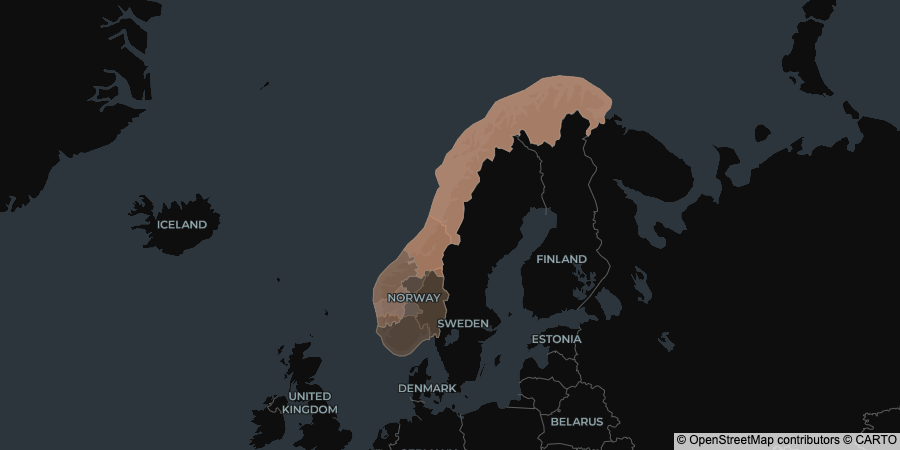

In [ ]:
# check: price areas (EL) and water areas (VASS) on one map
geo = json.load(open("data/areas.geojson"))
fig = go.Figure()
for kind in ("EL", "VASS"):
    sub = {"type": "FeatureCollection", "features": [f for f in geo["features"] if f["properties"]["type"] == kind]}
    names = [f["properties"]["area"] for f in sub["features"]]
    fig.add_trace(go.Choroplethmap(geojson=sub, locations=names, z=list(range(len(names))), featureidkey="properties.area",
                                   colorscale=[[0, "#2C3E57"], [1, SLATE]] if kind == "EL" else [[0, "#6B4A2C"], [1, COPPER]],
                                   marker=dict(opacity=0.6, line=dict(width=1, color="#8A8279")), showscale=False, name=kind))
fig.update_layout(map=dict(style="carto-darkmatter", center=dict(lat=65, lon=13), zoom=2.6), margin=dict(l=0, r=0, t=0, b=0), height=450)
show(fig)


* **GeoJSON:** the cell above converts the shapefiles from part 3 (same merging of the precipitation regions, RS+RØ and RM+RN) to data/areas.geojson: 5 price areas (EL), 3 water areas (VASS) and Norway (NO), about 0.2 MB. The app reads the file, so it does not need geopandas.
* **Map (on *Home*):** go.Choroplethmap with the GeoJSON of the chosen area type (EL, VASS or NO). Outlines are drawn for every area, also those without a value. The map sits in an st.expander that is open at the start, and a line below shows the current choice when it is closed.
* **Colouring:** *Show on the map* offers the fill degree and the weather properties (temperature, precipitation, rain, snowfall, wind speed, wind gusts) as the mean over the chosen period. The colours are transparent (opacity 0.75) and the colour bar explains the value.
* **Time:** an st.select_slider with a range of months. Fill degree = the last week of the period, weather = the mean of the period.
* **Click:** a click gives the area a thick blue outline and stores area and area type in st.session_state, so the other pages open with it. The *Area* selector does the same.
* **SATV and LOF:** *Weather anomalies* has a weather property selector in both tabs (temperature is the default), next to the shared area and the year.

### Meteorology and Magasinstatistikk
- Transform our Sliding Window Correlation with selectable lag and window length into a Streamlit equivalent with Plotly graphics (or equivalent).
    - Include a selector for meteorological properties and correlate against a representative variable from the Magasinstatistikk.
    - After implementation, play with the controls and check if you can spot any changes in correlations that can be interesting for predictions. Report your findings in the Jupyter Notebook log.

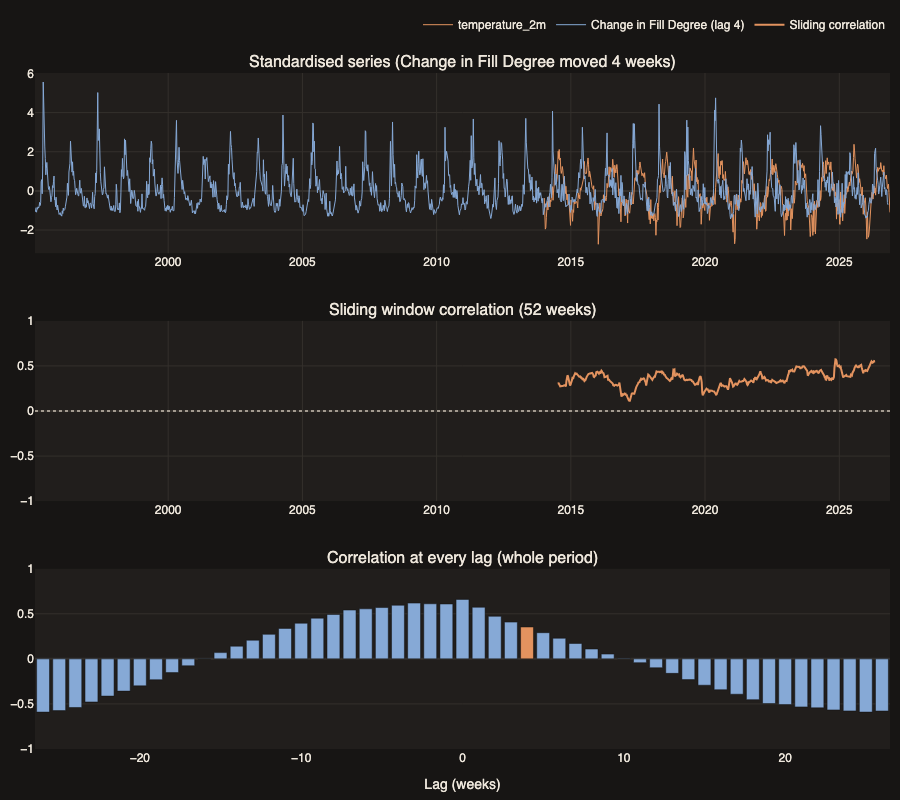

,weather,Magasinstatistikk,r at lag 0,"strongest lag, weather first (weeks)",r at that lag,sliding min,year of min,sliding max,year of max
0,temperature_2m,Fill Degree,0.34,10,0.77,-0.17,2024,0.59,2015
1,temperature_2m,Change in Fill Degree,0.66,0,0.66,0.54,2014,0.80,2026
2,precipitation,Fill Degree,0.23,1,0.23,-0.13,2015,0.54,2018
3,precipitation,Change in Fill Degree,0.22,0,0.22,-0.15,2020,0.55,2026
4,snowfall,Fill Degree,-0.22,8,-0.51,-0.67,2015,0.27,2024
5,snowfall,Change in Fill Degree,-0.29,24,0.44,-0.53,2015,-0.15,2018


In [ ]:
# EL 3: weekly weather against the fill degree and its weekly change
ex = weekly_extra(weather=weather)
targets = {"Fill Degree": fill.rename("Fill Degree"), "Change in Fill Degree": fill.diff().rename("Change in Fill Degree")}
fig, s = sliding_correlation(ex["temperature_2m"], targets["Change in Fill Degree"], lag=4, window=52)
show(fig)

# all weather variables, both targets, lag 0: strongest link and how much it varies
rows = []
for var in WX:
    for tname, y in targets.items():
        _, s = sliding_correlation(ex[var], y, lag=0, window=52)
        roll = s["rolling"].dropna()
        rows.append({"weather": var, "Magasinstatistikk": tname, "r at lag 0": round(s["overall"], 2),
                     "strongest lag, weather first (weeks)": s["best_lag"], "r at that lag": round(s["best_corr"], 2),
                     "sliding min": round(roll.min(), 2), "year of min": roll.idxmin().year,
                     "sliding max": round(roll.max(), 2), "year of max": roll.idxmax().year})
findings = pd.DataFrame(rows)
display(findings)


* **Page *Correlation*:** the sliding-window correlation from the book (rolling(window, center=True).corr(...)) with sliders for **lag** (-26 to 26 weeks) and **window** (8 to 156 weeks), a weather property selector and a selector for the Magasinstatistikk variable (*Fill Degree*, or *Change in Fill Degree*). Three Plotly panels show the two standardised series, the sliding correlation and the correlation at every lag.
* **Findings:** the table above is from playing with the controls (lag 0, window 52) for EL 3. The strongest lag is searched among 0 to 26 weeks (weather first), because only then the weather can predict the reservoir. The summary is in the *Developers log*.

### Forecasting of water magazine filling
- Create an interface for SARIMAX/Machine Learning where all the relevant parameters and exogenous variables are selectable.
    - Let the user choose the timeframe for the training data and the forecast horizon (let this be synced with the map time frame).
    - Forecast water magazine filling with dynamic forecasting, including any exogenous variables that are selected.
    - Plot the results using Plotly animation.
    - See Bonus exercises regarding confidence intervals.

### <font color="green">answer </font>
* **Page *Forecast* (group *Outlook*):** controls for `p, d, q`, the seasonal `m, sp, sd, sq`, learning rate, passes, history length, forecast period, the extra variables (weather, EUR/NOK, USD/NOK, ENTSO-E net export), the weather in the forecast weeks (seasonal mean or real values for a back-test) and the confidence interval. The defaults come from data/forecast_defaults.json, written by the best realistic setting of the back-test.
* **Time frame:** the page uses the Home time frame (st.session_state.sel_period). *Back-test* trains on the history before the period and forecasts the period (max 52 weeks), so it can be compared with the real fill degree. *History (weeks)* (52 to 780) sets the training length and *Training weeks* shows the exact period. *Forecast the coming weeks* trains up to the last data week and forecasts 1 to 52 weeks (*Weeks ahead*).
* **Dynamic forecasting** with the chosen extra variables is forecast_fill (model.forecast(horizon, xs)).
* **Plotly animation:** forecast_plot has Play/Pause and a slider, and the forecast and its interval grow week by week.
* **Confidence interval:** see the bonus below.

## Streamlit app, bonus content. Select at least one task from this list. Report in the log which one you chose.
### Waiting time
- Use progress bars, spinners, or similar to indicate work in progress.
- Cache everything that is possible to cache.
### Error handling
- Try to incorporate checks in the app that handle missing data connections (API and database) and NaN/missing values in the data.
- Catch the errors and give useful feedback instead of crashing or giving cryptic error messages.
### Elevation
- open-meteo also has an elevation API. This can be used to add elevation information to selected points in the main map or to make a separate elevation map.
### Confidence intervals in SARIMAX
- Use loss=optim.losses.Quantile to predict confidence intervals for the forecasts.


I chose **Waiting time**, **Error handling** and **Confidence intervals in SARIMAX**.
* **Waiting time:** st.progress while weather is downloaded year by year, st.spinner for single downloads and the model, and st.cache_data for NVE (1 hour), GeoJSON, exchange rates (1 hour), MongoDB (1 hour), weather (24 hours) and the forecast.
* **Error handling:** every download is wrapped. A failing NVE, Open-Meteo, Norges Bank or MongoDB connection gives a message that names the source and says what to do, and the page stops with st.stop(). Missing values are interpolated (weather, fill degree) or dropped (training weeks), and the pages say so when too little data is left.
* **Confidence intervals:** forecast_fill(..., interval=True) trains two more models with optim.losses.Quantile(0.1) and Quantile(0.9). The table above shows the coverage of the 80 % interval for different numbers of passes. The page draws the interval as a transparent band that grows with the animation.

## Screencast
- 10-12-minute screencast where you:
    - show your own face when talking (e.g., in a corner of the video),
    - briefly showcase your interaction with all pages of your running app (2-4 minutes),
    - explain your visual design choices and app organisation, including how navigation works and which controllers affect what (1-2 minutes),
    - show and explain key Python code related to data storage and transfer, including caching choices and user feedback for time-consuming calls (3-5 minutes),
    - highlight other parts of the project that deserve some screen time, e.g., struggles, victories, smart solutions, things you've learned (1-3 minutes).
    - If you want, you can combine points above, as long as you give emphasis approximately as the minute indications say.
- Canvas does not permit upload of more than one file in the assignment.
- If you make a screencast in Panopto, you can share a link to your video and add the link to the Jupyter Notebook or as a submission comment (make sure the file permissions are open for anyone, as the default is locked and private).
- If you use a different tool for making the screencast, you can upload your video to the GitHub repo.


In [ ]:
from IPython.display import Video
Video("../video/video.ind320-kompresed- part 4.mp4", width=600)


### <font color="red"> **I wasnt able to put the screencast video in full quality here beacasue the file was way to large , so i made an onedrive link with accsess to everyone with a link (Personer i Norwegian Un...ife Sciences) , hope it works! :** </font> 

*Onedrive video link* [Click here](https://eduumb-my.sharepoint.com/:v:/g/personal/dakshiken_santhakumar_nmbu_no/IQBqoQFtBQW8R4mfRddTakmcAaXCtmNuU3aCs6UJAAUqMnY?nav=eyJyZWZlcnJhbEluZm8iOnsicmVmZXJyYWxBcHAiOiJPbmVEcml2ZUZvckJ1c2luZXNzIiwicmVmZXJyYWxBcHBQbGF0Zm9ybSI6IldlYiIsInJlZmVycmFsTW9kZSI6InZpZXciLCJyZWZlcnJhbFZpZXciOiJNeUZpbGVzTGlua0NvcHkifX0&e=mfGeLY)



## AI usage

In developing this project, I handled the vast majority of the work, architecture, and coding myself. Artificial intelligence (primarily Claude, with some supplementary use of Gemini) was used as a supporting tool and discussion partner along the way. The AI tools served as a supplement to get quick input on troubleshooting, check syntax for certain APIs (such as Norges Bank and Open-Meteo), get suggestions for technical challenges related to time zones and frameworks and to write comments for the code and make it look clean beacuse its faster and efficent. All core logic, structure, customization, and the final integration into both the Jupyter notebook and the Streamlit application were written, tested, and put together by me.

## Developers log

I started by removing the old pages from part 3 and building the menu again. The app now has Home and seven pages in three groups: Status (Reservoirs, Cross-border flows, Exchange rates), Patterns (Seasonality, Weather anomalies, Correlation) and Outlook (Forecast). The table with small lines and the reservoir plot became one page. The page files also moved from `pages/` to `views/`, because pressing F5 on a page in `pages/` started that file alone, skipped `streamlit_app.py` and crashed the app.

When I tested the first version myself I did not understand what the map was for. Home now explains the project in three steps and has the map and the selectors in a box that can be closed. A click on the map stores the area in `st.session_state`, so the other pages open on the same area. Widget values disappear when their page is not shown, so the shared choices (`sel_area`, `sel_period`) are plain keys and the widgets write back with callbacks. Every page has a short explanation, help texts and previous/next links, and a glossary explains words like fill degree and lag. The theme is dark now, with one Plotly template in `modules/theme.py` for all figures, and the modules are generated from the notebook.

The timezone check showed that the sources differ: a weekly date (Magasinstatistikk), UTC (Open-Meteo, ENTSO-E) and one rate per business day (Norges Bank). Open-Meteo's `timezone` option ignores clock changes according to its documentation, so I convert with pandas. Everything is averaged to weeks, because hourly data has 168 times more points than the weekly target.

The forecast uses River's SNARIMAX. The future weather is unknown, so the page uses the seasonal mean by default and the real weather only in a back-test. The best realistic setting from the back-test is saved in `data/forecast_defaults.json`. With one pass the intervals were too wide (see the interval table). Open-Meteo allows 600 calls per minute, so multi-year downloads use 10 locations and are cached per year. Bonus tasks: Waiting time, Error handling and Confidence intervals.

ENTSO-E flows exist only from 2024 in my database, so a model with net export trains on about two years and I have not compared it fairly with the other settings.

In [ ]:
# findings from playing with the sliding window correlation (calculated from the table above, so the text always matches the data)
strongest = findings.loc[findings["r at that lag"].abs().idxmax()]
swing = findings.assign(span=findings["sliding max"] - findings["sliding min"]).sort_values("span").iloc[-1]
display(Markdown(
    f"**Correlation findings (EL 3):** the strongest relation with the weather coming first is between {strongest['weather']} and {strongest['Magasinstatistikk']}, "
    f"r = {strongest['r at that lag']} at a lag of {strongest['strongest lag, weather first (weeks)']} weeks (r = {strongest['r at lag 0']} at lag 0). "
    f"The 52-week sliding correlation of {swing['weather']} against {swing['Magasinstatistikk']} moves between {swing['sliding min']} (around {swing['year of min']}) "
    f"and {swing['sliding max']} (around {swing['year of max']}). Both series have a strong annual cycle, so a large part of every correlation is just the season. A relation that changes this much over time is a warning for forecasting: "
    f"a weather variable helps most when its sliding correlation is stable, and a lag with a strong correlation is a candidate for an exogenous variable."))

**Correlation findings (EL 3):** the strongest relation with the weather coming first is between temperature_2m and Fill Degree, r = 0.77 at a lag of 10 weeks (r = 0.34 at lag 0). The 52-week sliding correlation of snowfall against Fill Degree moves between -0.67 (around 2015) and 0.27 (around 2024). Both series have a strong annual cycle, so a large part of every correlation is just the season. A relation that changes this much over time is a warning for forecasting: a weather variable helps most when its sliding correlation is stable, and a lag with a strong correlation is a candidate for an exogenous variable.